# Sequence content of barcodes with zero or low counts

Printed-area features (dead band excluded), minus a two-feature border and the Greedy dark spots, are grouped at $r = 7$ as zero (0 reads), low (1), medium (2–4) and high (>4).

Every comparison is reported on raw counts and, where marked, on the ratio of a feature's count to the median of its 5×5 neighbourhood. Sampling is the Poisson / negative-binomial baseline with that local mean. Sequence tests use Mann–Whitney U tests with Cliff's delta and Benjamini–Hochberg correction. Models are negative binomial GLMs.

Feature table: `features.py`. Tests and models: `analyse.py`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})
OUT = Path(".")

import features as feat
import analyse as an

if not (OUT / "barcode_features.csv").exists():
    feat.main()
if not (OUT / "group_tests.csv").exists():
    an.main()

df = an.add_groups(pd.read_csv(OUT / "barcode_features.csv"))
if (OUT / "simulation_recall.csv").exists():
    sim = pd.read_csv(OUT / "simulation_recall.csv")
    df = df.merge(sim[["layout", "barcode", "sim_recall", "sim_n_correct"]], on=["layout", "barcode"], how="left")
sampling = pd.read_csv(OUT / "sampling_baseline.csv")
tests = pd.read_csv(OUT / "group_tests.csv")
kmers = pd.read_csv(OUT / "kmer_enrichment_k3.csv")
pos = pd.read_csv(OUT / "position_composition.csv")
units = pd.read_csv(OUT / "unit_level.csv")
models = pd.read_csv(OUT / "nb_models.csv")
stab = pd.read_csv(OUT / "group_stability.csv")
display(sampling.round(3))
display(stab.round(3))
display(units.round(3))

,layout,n_analysis,mean_reads,variance,var_over_mean,zero_observed,zero_poisson,zero_nb,zero_poisson_local,excess_zeros_poisson,excess_zeros_local,mean_umis
0,Dual barcodes,70224,2.387,7.295,3.057,0.263,0.092,0.273,0.254,0.171,0.008,1.991
1,Greedy + 2-OPT,72240,0.879,1.440,1.638,0.486,0.415,0.507,0.639,0.071,-0.152,0.859
2,Zipcodes,74613,2.333,7.455,3.195,0.261,0.097,0.291,0.309,0.164,-0.047,2.302


,layout,threshold,zero,medium,low,high,n
0,Dual barcodes,5,0.357,0.312,0.233,0.098,70224
1,Dual barcodes,6,0.297,0.343,0.223,0.136,70224
2,Dual barcodes,7,0.263,0.358,0.216,0.164,70224
3,Greedy + 2-OPT,5,0.647,0.103,0.248,0.003,72240
4,Greedy + 2-OPT,6,0.552,0.160,0.279,0.008,72240
5,Greedy + 2-OPT,7,0.486,0.205,0.295,0.014,72240
6,Zipcodes,5,0.390,0.279,0.258,0.073,74613
7,Zipcodes,6,0.309,0.326,0.245,0.119,74613
8,Zipcodes,7,0.261,0.351,0.233,0.155,74613


,layout,unit,n_units,between_unit_var,spearman_G,p_G
0,Dual barcodes,half1,59,0.084,0.048,0.719
1,Dual barcodes,half2,77,0.331,-0.001,0.995
2,Zipcodes,half1,323,2.075,-0.863,0.000
3,Zipcodes,half2,231,2.123,-0.877,0.000


## Count groups and sampling baseline

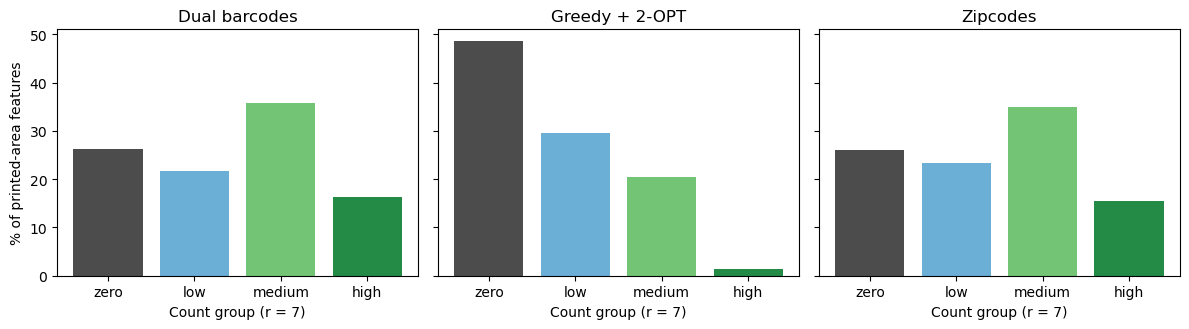

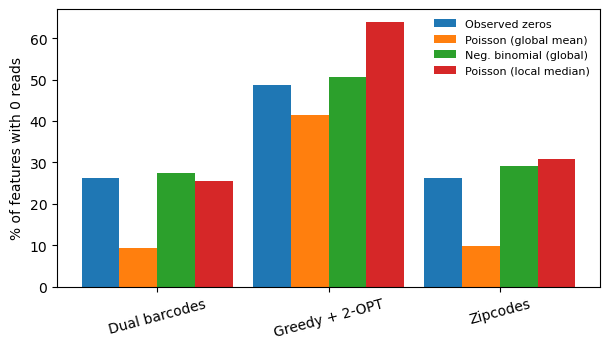

In [2]:
order = ["zero", "low", "medium", "high"]
layouts = list(df.layout.unique())
fig, axes = plt.subplots(1, len(layouts), figsize=(4 * len(layouts), 3.4), sharey=True)
for ax, name in zip(np.atleast_1d(axes), layouts):
    a = df[(df.layout == name) & df.analysis_set]
    counts = a.count_group.value_counts().reindex(order).fillna(0)
    ax.bar(order, 100 * counts / counts.sum(), color=["#4c4c4c", "#6baed6", "#74c476", "#238b45"])
    ax.set_title(name)
    ax.set_xlabel("Count group (r = 7)")
axes[0].set_ylabel("% of printed-area features")
fig.tight_layout()
fig.savefig(OUT / "count_groups.pdf")
plt.show()

fig, ax = plt.subplots(figsize=(6.2, 3.6))
x = np.arange(len(sampling))
w = 0.22
ax.bar(x - 1.5 * w, sampling.zero_observed * 100, w, label="Observed zeros")
ax.bar(x - 0.5 * w, sampling.zero_poisson * 100, w, label="Poisson (global mean)")
ax.bar(x + 0.5 * w, sampling.zero_nb * 100, w, label="Neg. binomial (global)")
ax.bar(x + 1.5 * w, sampling.zero_poisson_local * 100, w, label="Poisson (local median)")
ax.set_xticks(x)
ax.set_xticklabels(sampling.layout, rotation=15)
ax.set_ylabel("% of features with 0 reads")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "sampling_baseline.pdf")
plt.show()

## Sequence features: zero vs high

,layout,contrast,feature,n_left,n_right,median_left,median_right,cliffs_delta,p_raw,p_adj,sig
0,Dual barcodes,zero_vs_high,G_frac,18435,11488,0.250,0.167,0.762,0.0,0.0,True
14,Dual barcodes,zero_vs_high,mean_4mer_share,18435,11488,11621.636,12174.409,-0.326,0.0,0.0,True
69,Zipcodes,zero_vs_high,G_frac_half1,19495,11589,0.278,0.167,0.706,0.0,0.0,True
70,Zipcodes,zero_vs_high,G_frac_half2,19495,11589,0.278,0.167,0.700,0.0,0.0,True
71,Zipcodes,zero_vs_high,GC_frac,19495,11589,0.528,0.417,0.701,0.0,0.0,True
72,Zipcodes,zero_vs_high,purine_frac,19495,11589,0.500,0.444,0.340,0.0,0.0,True
74,Zipcodes,zero_vs_high,GG_count,19495,11589,2.000,1.000,0.725,0.0,0.0,True
68,Zipcodes,zero_vs_high,G_frac,19495,11589,0.278,0.139,0.910,0.0,0.0,True
8,Dual barcodes,zero_vs_high,G4_score,18435,11488,0.306,0.194,0.720,0.0,0.0,True
6,Dual barcodes,zero_vs_high,GG_count,18435,11488,1.000,0.000,0.452,0.0,0.0,True


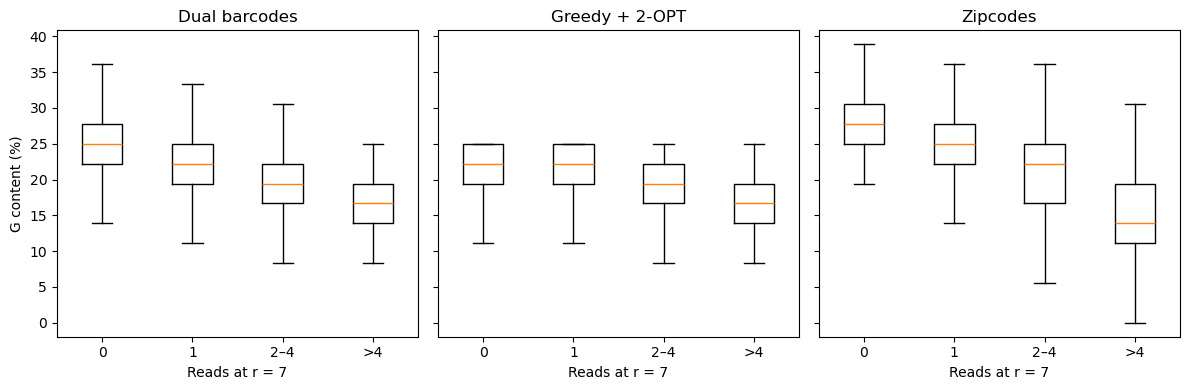

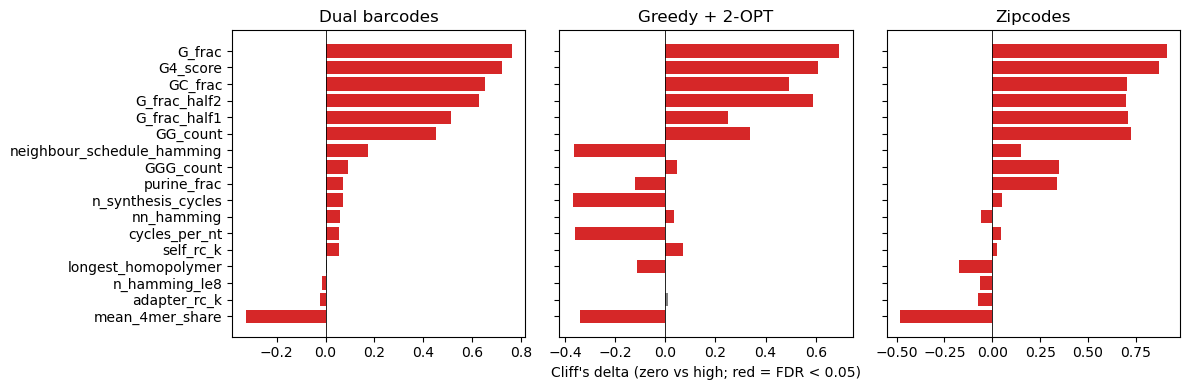

In [3]:
show = tests[tests.contrast == "zero_vs_high"].copy()
show["sig"] = show.p_adj < 0.05
top = show.sort_values("p_adj").groupby("layout").head(8)
display(top.round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, layouts):
    a = df[(df.layout == name) & df.analysis_set]
    data = [a.loc[a.count_group == g, "G_frac"] * 100 for g in order]
    ax.boxplot(data, labels=["0", "1", "2–4", ">4"], showfliers=False)
    ax.set_title(name)
    ax.set_xlabel("Reads at r = 7")
axes[0].set_ylabel("G content (%)")
fig.tight_layout()
fig.savefig(OUT / "G_frac_by_group.pdf")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, layouts):
    s = show[show.layout == name].sort_values("cliffs_delta")
    colors = ["tab:red" if p < 0.05 else "grey" for p in s.p_adj]
    ax.barh(s.feature, s.cliffs_delta, color=colors)
    ax.axvline(0, color="black", lw=0.6)
    ax.set_title(name)
axes[1].set_xlabel("Cliff's delta (zero vs high; red = FDR < 0.05)")
fig.tight_layout()
fig.savefig(OUT / "cliffs_delta_zero_vs_high.pdf")
plt.show()

## Difference logos and 3-mer enrichment

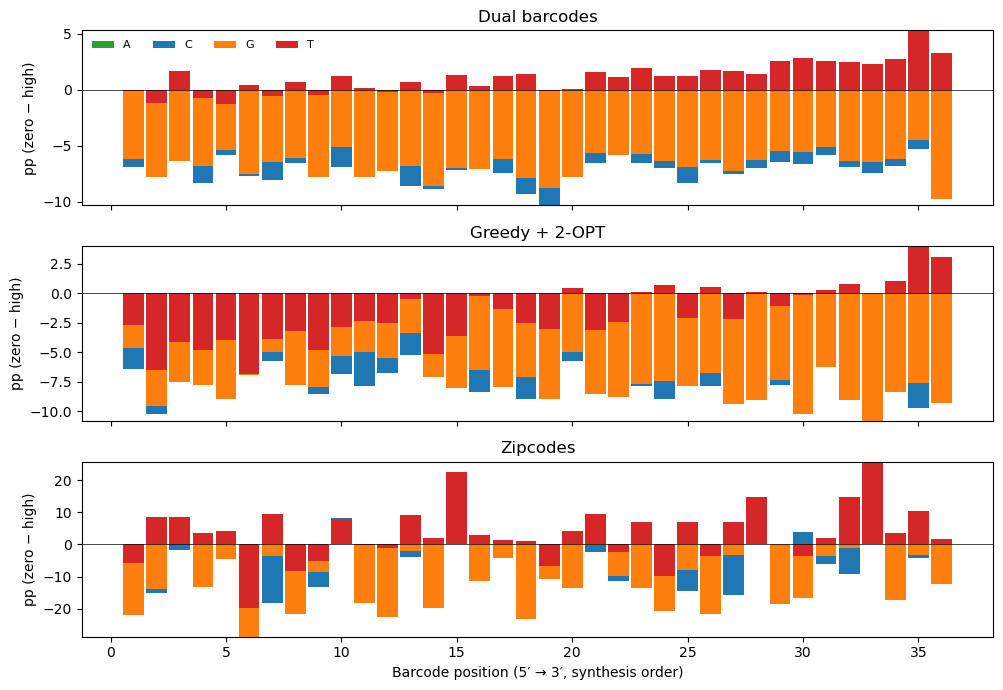

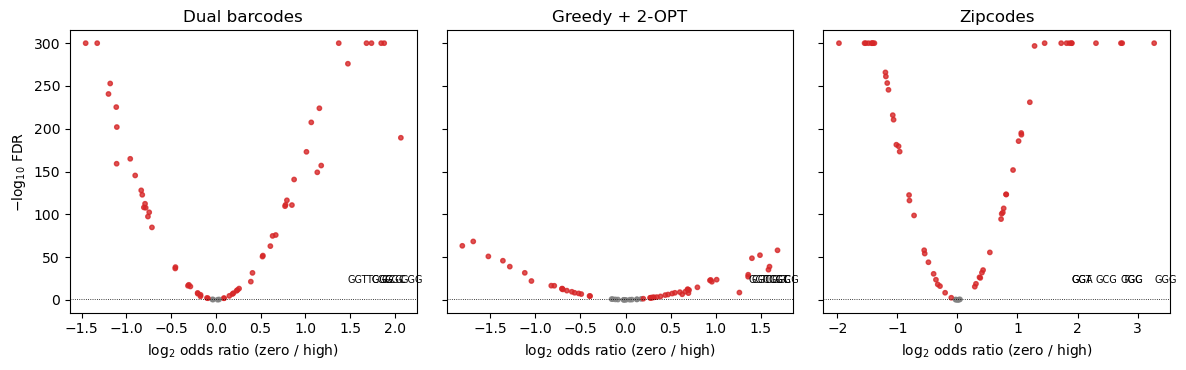

,layout,k,kmer,frac_zero,frac_high,oddsratio,p_raw,p_adj,log2_or
154,Zipcodes,3,GGT,0.438010,0.172319,3.743571,0.000000e+00,0.000000e+00,1.904415
162,Zipcodes,3,GGG,0.412670,0.067650,9.683431,0.000000e+00,0.000000e+00,3.275518
166,Zipcodes,3,ATA,0.347012,0.580637,0.383818,0.000000e+00,0.000000e+00,-1.381506
168,Zipcodes,3,GGA,0.519672,0.224610,3.734936,0.000000e+00,0.000000e+00,1.901083
21,Dual barcodes,3,CGG,0.376512,0.153116,3.340052,0.000000e+00,0.000000e+00,1.739871
139,Zipcodes,3,GCG,0.490895,0.163086,4.948192,0.000000e+00,0.000000e+00,2.306902
48,Dual barcodes,3,ACA,0.491782,0.726236,0.364771,0.000000e+00,0.000000e+00,-1.454935
173,Zipcodes,3,ATT,0.318902,0.553628,0.377508,0.000000e+00,0.000000e+00,-1.405420
149,Zipcodes,3,CGG,0.410208,0.173527,3.312589,0.000000e+00,0.000000e+00,1.727959
175,Zipcodes,3,AGG,0.492742,0.216067,3.524364,0.000000e+00,0.000000e+00,1.817363


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, name in zip(axes, layouts):
    p = pos[(pos.layout == name)]
    z = p[p.group == "zero"].pivot(index="position", columns="base", values="frequency")
    h = p[p.group == "high"].pivot(index="position", columns="base", values="frequency")
    diff = (z - h) * 100
    bottom = np.zeros(len(diff))
    for b, c in zip("ACGT", ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
        ax.bar(diff.index, diff[b], bottom=bottom, color=c, width=0.9, label=b)
        bottom = bottom + diff[b].to_numpy()
    ax.axhline(0, color="black", lw=0.5)
    ax.set_ylabel("pp (zero − high)")
    ax.set_title(name)
axes[0].legend(frameon=False, ncol=4, fontsize=8)
axes[-1].set_xlabel("Barcode position (5′ → 3′, synthesis order)")
fig.tight_layout()
fig.savefig(OUT / "difference_logos.pdf")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, name in zip(axes, layouts):
    k = kmers[kmers.layout == name]
    ax.scatter(k.log2_or, -np.log10(k.p_adj.clip(lower=1e-300)), s=10, c=np.where(k.p_adj < 0.05, "tab:red", "grey"), alpha=0.8)
    ax.axhline(-np.log10(0.05), ls=":", color="black", lw=0.6)
    ax.set_title(name)
    ax.set_xlabel(r"log$_2$ odds ratio (zero / high)")
    sig = k[k.p_adj < 0.05].nlargest(6, "log2_or")
    for _, row in sig.iterrows():
        ax.annotate(row.kmer, (row.log2_or, -np.log10(max(row.p_adj, 1e-20))), fontsize=7)
axes[0].set_ylabel(r"−log$_{10}$ FDR")
fig.tight_layout()
fig.savefig(OUT / "kmer_enrichment.pdf")
plt.show()
display(kmers[kmers.p_adj < 0.05].sort_values("p_adj").groupby("layout").head(8))

## Negative binomial models

,layout,model,pseudo_r2,deviance,aic,n,poisson_deviance
0,Dual barcodes,NaN,4.440892e-16,69720.602501,288632.476326,70224,NaN
1,Dual barcodes,spatial,3.175145e-02,67506.871959,286422.745783,70224,NaN
2,Dual barcodes,sequence,2.610649e-01,51519.001024,270446.874849,70224,NaN
3,Dual barcodes,spatial_offset,-4.440892e-16,60481.139477,279393.013301,70224,NaN
4,Dual barcodes,sequence_plus_offset,1.777950e-01,49727.897997,268655.771821,70224,NaN
5,Dual barcodes,both,2.924094e-01,49333.645806,268265.519630,70224,NaN
6,Dual barcodes,cv_offset,NaN,NaN,NaN,70224,161334.534173
7,Dual barcodes,cv_seq+offset,NaN,NaN,NaN,70224,125209.284750
8,Greedy + 2-OPT,NaN,1.110223e-16,61996.061500,187599.262852,72240,NaN
9,Greedy + 2-OPT,spatial,6.234754e-02,58130.759608,183737.960960,72240,NaN


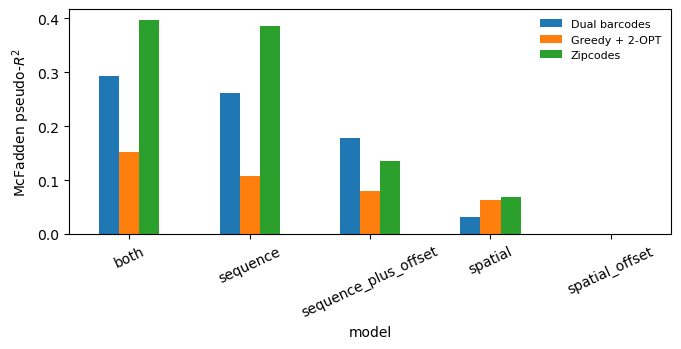

In [5]:
display(models)
r2 = models.dropna(subset=["pseudo_r2"])
fig, ax = plt.subplots(figsize=(7, 3.6))
wide = r2.pivot_table(index="model", columns="layout", values="pseudo_r2")
wide.plot(kind="bar", ax=ax, rot=25)
ax.set_ylabel("McFadden pseudo-$R^2$")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "nb_models.pdf")
plt.show()

## Simulated recall vs real counts

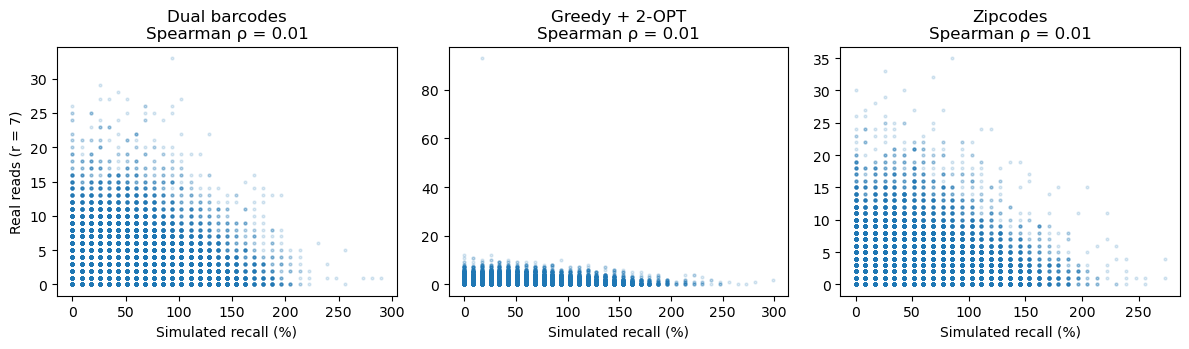

,layout,spearman,p,n
0,Dual barcodes,0.0066,0.0808,70224
1,Greedy + 2-OPT,0.0060,0.1071,72240
2,Zipcodes,0.0051,0.1663,74613


In [6]:
if "sim_recall" in df.columns:
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    for ax, name in zip(axes, layouts):
        a = df[(df.layout == name) & df.analysis_set].dropna(subset=["sim_recall"])
        ax.scatter(a.sim_recall * 100, a.reads_r7, s=4, alpha=0.15)
        rho, p = spearmanr(a.sim_recall, a.reads_r7)
        ax.set_title(f"{name}\nSpearman ρ = {rho:.2f}")
        ax.set_xlabel("Simulated recall (%)")
        rows.append({"layout": name, "spearman": rho, "p": p, "n": len(a)})
    axes[0].set_ylabel("Real reads (r = 7)")
    fig.tight_layout()
    fig.savefig(OUT / "sim_recall_vs_real_counts.pdf")
    plt.show()
    display(pd.DataFrame(rows).round(4))
else:
    print("Run decoding_rescue.py to add simulated recall.")